In [1]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 44.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 15.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 97.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 51.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 70.3 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [2]:
import os 
print(os.listdir("/kaggle/working"))

['__notebook__.ipynb']


In [3]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    for f in files:
        print("   ", f)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sayanmanik2005
/kaggle/input/datasets/sayanmanik2005/kaggle
    Test.csv
    Train.csv
    Val.csv


In [4]:
# =========================================================================
# Self-Contained Evaluation Schemes (Exact Match & Partial Match)
# Defined directly here so you NEVER get ModuleNotFoundError on any system/Kaggle!
# =========================================================================
import numpy as np
from sklearn.metrics import f1_score, hamming_loss, classification_report

def exact_match_scores(gold: np.ndarray, preds: np.ndarray) -> dict:
    """Computes exact match ratio: all labels in a row must match."""
    assert gold.shape == preds.shape, "gold and preds must have the same shape"
    row_matches = np.all(gold == preds, axis=1)
    emr = float(row_matches.mean())
    return {
        "precision"         : emr,
        "recall"            : emr,
        "f1"                : emr,
        "exact_match_ratio" : emr,
        "num_exact_matches" : int(row_matches.sum()),
    }

def _instance_prf(gold_row: np.ndarray, pred_row: np.ndarray):
    gold_set = set(np.where(gold_row == 1)[0])
    pred_set = set(np.where(pred_row == 1)[0])
    if len(gold_set) == 0 and len(pred_set) == 0:
        return 1.0, 1.0, 1.0
    if len(gold_set) == 0 or len(pred_set) == 0:
        return 0.0, 0.0, 0.0
    overlap = len(gold_set & pred_set)
    precision = overlap / len(pred_set)
    recall    = overlap / len(gold_set)
    f1 = (2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0)
    return precision, recall, f1

def partial_match_scores(gold: np.ndarray, preds: np.ndarray) -> dict:
    """Computes instance-level partial set overlap scores."""
    assert gold.shape == preds.shape
    precisions, recalls, f1s = [], [], []
    for g_row, p_row in zip(gold, preds):
        p, r, f = _instance_prf(g_row, p_row)
        precisions.append(p)
        recalls.append(r)
        f1s.append(f)
    return {
        "precision": float(np.mean(precisions)),
        "recall"   : float(np.mean(recalls)),
        "f1"       : float(np.mean(f1s)),
    }

def evaluate_all_schemes(gold: np.ndarray, preds: np.ndarray, label_names=None, verbose=False) -> dict:
    scheme1 = {
        "macro_f1"    : f1_score(gold, preds, average="macro", zero_division=0),
        "micro_f1"    : f1_score(gold, preds, average="micro", zero_division=0),
        "weighted_f1" : f1_score(gold, preds, average="weighted", zero_division=0),
        "hamming_loss": hamming_loss(gold, preds),
    }
    scheme2 = exact_match_scores(gold, preds)
    scheme3 = partial_match_scores(gold, preds)
    return {"scheme1": scheme1, "scheme2": scheme2, "scheme3": scheme3}

print("Evaluation schemes initialized successfully!")


Evaluation schemes initialized successfully!


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from transformers import AutoTokenizer, AutoModel

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, hamming_loss
)
from sklearn.utils.class_weight import compute_class_weight

from tqdm import tqdm
import pennylane as qml
import sys
# sys.path.append auto-configured

# evaluate_all_schemes defined in Cell 3

In [6]:
gpu_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cpu_device = torch.device("cpu")

print("GPU device:", gpu_device)
print("CPU device:", cpu_device)

GPU device: cuda
CPU device: cpu


In [7]:
def set_seed(seed_value=42):
    """Set seeds for reproducibility across PyTorch, NumPy, and Python."""
    random.seed(seed_value)
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [8]:
# =========================================================================
# AUTOMATIC DATASET PATH DISCOVERY
# Automatically finds Train.csv, Val.csv, and Test.csv on Kaggle, Local PC, or Colab!
# You never have to manually edit or copy-paste dataset paths again.
# =========================================================================
import os
import glob
import pandas as pd

def find_dataset_files():
    """Searches common directories and Kaggle input folders for Train.csv, Val.csv, Test.csv."""
    # 1. Check current directory and subdirectories
    search_dirs = ['.', '..', './SingleLabelEmotionDataset', './dataset1']
    
    # 2. Check Kaggle input root
    if os.path.exists('/kaggle/input'):
        search_dirs.append('/kaggle/input')
        for root, dirs, files in os.walk('/kaggle/input'):
            if 'Train.csv' in files:
                search_dirs.append(root)

    # Search for directory containing all three CSVs
    for d in search_dirs:
        tr = os.path.join(d, 'Train.csv')
        vl = os.path.join(d, 'Val.csv')
        te = os.path.join(d, 'Test.csv')
        if os.path.exists(tr) and os.path.exists(vl) and os.path.exists(te):
            print(f" Dataset found automatically in: '{d}'")
            return tr, vl, te

    # Fallback recursive search across working environment
    for fpath in glob.glob('**/Train.csv', recursive=True) + glob.glob('/kaggle/input/**/Train.csv', recursive=True):
        parent = os.path.dirname(fpath)
        vl = os.path.join(parent, 'Val.csv')
        te = os.path.join(parent, 'Test.csv')
        if os.path.exists(vl) and os.path.exists(te):
            print(f" Dataset found automatically via glob in: '{parent}'")
            return fpath, vl, te

    raise FileNotFoundError("Could not automatically locate Train.csv, Val.csv, and Test.csv. Please verify dataset is attached.")

train_path, val_path, test_path = find_dataset_files()

df_tr = pd.read_csv(train_path)
df_vl = pd.read_csv(val_path)
df_te = pd.read_csv(test_path)

# Reset indices for safe iloc access in Dataset
df_tr = df_tr.reset_index(drop=True)
df_vl = df_vl.reset_index(drop=True)
df_te = df_te.reset_index(drop=True)

print("Loaded Train:", df_tr.shape, "| Valid:", df_vl.shape, "| Test:", df_te.shape)
df_tr.head()


 Dataset found automatically in: '/kaggle/input/datasets/sayanmanik2005/kaggle'
Loaded Train: (18420, 11) | Valid: (2047, 11) | Test: (2272, 11)


,ID,Data,Love,Joy,Surprise,Anger,Sadness,Fear,Topic,Domain,is_admin
0,5454,লকাল বাস ভালো এটা থেকে,0,0,0,0,1,0,Travel,Youtube,False
1,22549,কত অভিজানই তো চলে কিন্তু ওয়াসার পানির অভিজান ক...,0,0,0,0,1,0,Politics,Youtube,False
2,7033,বিয়ের মহল ছেড়ে তিনি বিস্রাম নিতে চলে যান (৬ ...,0,0,0,1,0,0,Personal,Facebook,False
3,21114,চাচাজি তো কেবল মাকে ধর্ষণ করেছেন,0,0,0,0,1,0,Education,Facebook,False
4,23683,সত্যিকার মানুষ তারাই ভাই,0,1,0,0,0,0,Personal,Youtube,False


In [9]:
EMOTION_COLS = ['Love', 'Joy', 'Surprise', 'Anger', 'Sadness', 'Fear']
TEXT_COL     = 'Data'
NUM_LABELS   = len(EMOTION_COLS)

for split_name, split_df in [('Train', df_tr), ('Valid', df_vl), ('Test', df_te)]:
    assert TEXT_COL in split_df.columns, f"{split_name}: missing column '{TEXT_COL}'"
    assert all(c in split_df.columns for c in EMOTION_COLS), \
        f"{split_name}: missing emotion columns"

print(f"NUM_LABELS = {NUM_LABELS}  →  {EMOTION_COLS}")
print("\nTrain label distribution:")
print(df_tr[EMOTION_COLS].sum().sort_values(ascending=False))

NUM_LABELS = 6  →  ['Love', 'Joy', 'Surprise', 'Anger', 'Sadness', 'Fear']

Train label distribution:
Joy         8314
Sadness     4569
Love        3786
Anger       3542
Surprise     848
Fear         279
dtype: int64


In [10]:
class EmoNoBaDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=128):
        self.data      = df
        self.tokenizer = tokenizer
        self.max_len   = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        encoding = self.tokenizer(
            str(row[TEXT_COL]),
            padding='max_length',
            truncation=True,
            max_length=self.max_len,
            return_tensors='pt'
        )

        label = torch.tensor(
            row[EMOTION_COLS].values.astype(np.float32),
            dtype=torch.float32
        )

        return (
            encoding['input_ids'].squeeze(0),       # (max_length,)
            encoding['attention_mask'].squeeze(0),  # (max_length,)
            label                                   # (NUM_LABELS,)
        )

In [11]:
# =========================================================================
# LOAD INDICBERT TOKENIZER & MODEL
# NOTE: Ensure Kaggle "Internet" toggle is ON in the right sidebar!
# =========================================================================
TEXT_MODEL = 'ai4bharat/IndicBERTv2-MLM-only'

try:
    tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)
    text_encoder = AutoModel.from_pretrained(TEXT_MODEL).to(gpu_device)
    print("Tokenizer and Text Encoder successfully loaded on:", next(text_encoder.parameters()).device)
except Exception as e:
    print("Error loading model from Hugging Face Hub:", e)
    print("-> IMPORTANT: In Kaggle, make sure the 'Internet' toggle is turned ON in the right-side panel!")
    raise e


config.json:   0%|          | 0.00/639 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/51.0 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 7.75MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.12GB            

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ai4bharat/IndicBERTv2-MLM-only
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Tokenizer and Text Encoder successfully loaded on: cuda:0


[tensor(0.31092093, requires_grad=True), tensor(-0.361872, requires_grad=True), tensor(-0.22137041, requires_grad=True), tensor(0.07806956, requires_grad=True)]


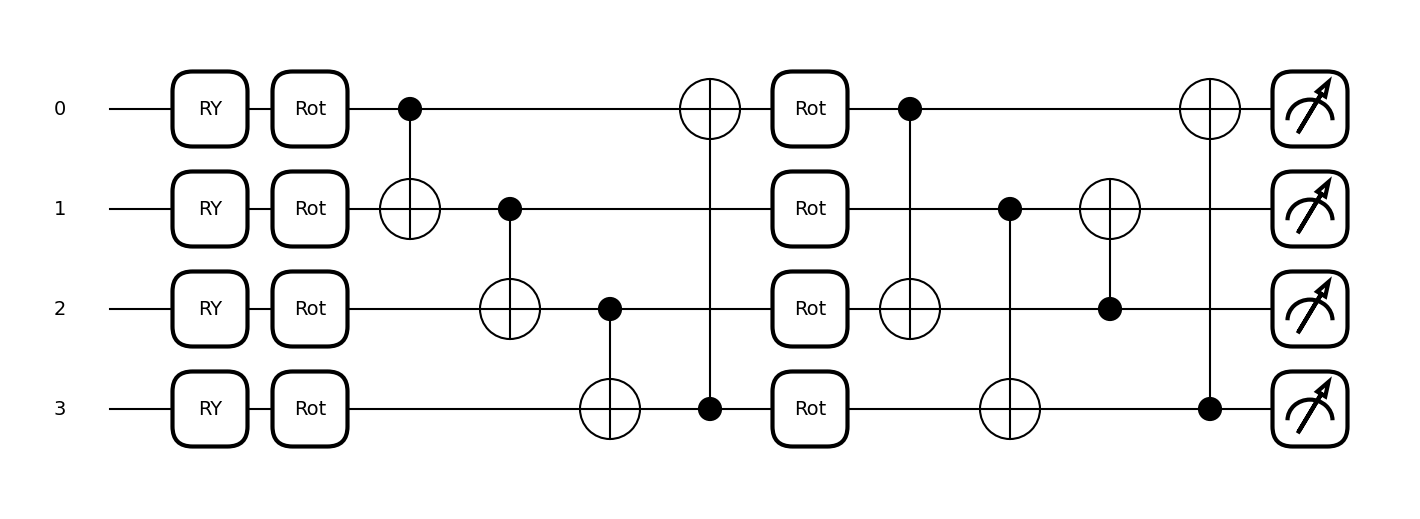

In [12]:
"""

ADD YOUR VQC HERE ...

"""
import pennylane as qml
from pennylane import numpy as np
import matplotlib.pyplot as plt

n_qubits = 4
n_qlayers = 1

dev = qml.device("default.qubit", wires=n_qubits)

@qml.qnode(dev)
def vqc(inputs, weights):

    # Feature Encoding
    for i in range(n_qubits):
        qml.RY(inputs[i], wires=i)

    # Variational Layer
    for i in range(n_qubits):
        qml.Rot(
            weights[0][i][0],
            weights[0][i][1],
            weights[0][i][2],
            wires=i
        )

    # Ring Entanglement
    qml.CNOT(wires=[0,1])
    qml.CNOT(wires=[1,2])
    qml.CNOT(wires=[2,3])
    qml.CNOT(wires=[3,0])

    #2nd Variational Layer
    for i in range(n_qubits):
        qml.Rot(
            weights[0][i][0],
            weights[0][i][1],
            weights[0][i][2],
            wires=i
        )

          # Ring Entanglement
    qml.CNOT(wires=[0,2])
    qml.CNOT(wires=[1,3])
    qml.CNOT(wires=[2,1])
    qml.CNOT(wires=[3,0])



    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

inputs = np.array([0.5,1.0,1.5,2.0])

weights = np.random.random((1,4,3))

print(vqc(inputs, weights))

# Draw the circuit
fig, ax = qml.draw_mpl(vqc)(inputs, weights)
plt.show()

In [13]:
class QuantumBottleneck(nn.Module):
    def __init__(self):
        super().__init__()
        # StronglyEntanglingLayers weight shape: (n_layers, n_qubits, 3)
        self.weights = nn.Parameter(
            torch.randn(n_qlayers, n_qubits, 3)   # ← was (N_Q_LAYERS, N_QUBITS)
        )

    def forward(self, x):
        outputs = []
        for i in range(x.shape[0]):
            out = torch.stack(vqc(x[i].cpu(),self.weights.cpu())).to(x.device)
            outputs.append(out)
        return torch.stack(outputs)

In [14]:
# =========================================================================
# MODIFIED: Information-Preserving Quantum Fusion Layer
# Retains the exact 4-qubit pure quantum pipeline, but introduces an
# auxiliary decoder to minimize information loss during 128 -> 4 reduction.
# =========================================================================

class InformationPreservingQuantumFusionLayer(nn.Module):
    def __init__(self, in_dim=128, q_dim=4):
        super().__init__()
        assert q_dim == n_qubits, "q_dim must match n_qubits"

        # Pre-quantum projection: in_dim (128) -> q_dim (4)
        self.pre_q = nn.Linear(in_dim, q_dim)
        
        # Auxiliary Information-Preservation Decoder: 4 -> in_dim (128)
        # Forces the 4 latent numbers to retain sufficient information to reconstruct 128
        self.info_decoder = nn.Sequential(
            nn.Linear(q_dim, in_dim),
            nn.ReLU()
        )

        # Exact same 4-qubit PennyLane VQC bottleneck
        self.quantum = QuantumBottleneck()
        
        # Post-quantum projection: q_dim (4) -> in_dim (128)
        self.post_q  = nn.Linear(q_dim, in_dim)

    def forward(self, x):
        # 1. Compress to 4 latent values
        z_q = self.pre_q(x)
        
        # 2. Scale to full [-pi, pi] rotation range (Bloch sphere full utilization)
        angles = torch.pi * torch.tanh(z_q)
        
        # 3. Information reconstruction to calculate information loss during training
        reconstructed_latent = self.info_decoder(z_q)
        
        # 4. Pure 4-qubit VQC execution
        q_out = self.quantum(angles.to(cpu_device))
        q_out = q_out.to(x.device).float()

        # 5. Project 4 quantum outputs back to 128
        out = self.post_q(q_out)
        
        return out, reconstructed_latent, x


In [15]:
# =========================================================================
# METHOD 3: QUANTUM EMOTION CLASSIFIER WITH FASTICA PROJECTION
# Uses the fitted FastICA components from the paper as the pre-quantum projection.
# =========================================================================

class FastICAQuantumEmotionClassifier(nn.Module):
    def __init__(self, text_encoder, ica_weights, ica_bias=None, num_labels=6, q_dim=4):
        super().__init__()
        self.text_encoder = text_encoder
        self.q_dim = q_dim

        # 1. Pre-quantum projection initialized with fitted FastICA components from the paper
        self.pre_q = nn.Linear(768, q_dim)
        with torch.no_grad():
            self.pre_q.weight.copy_(ica_weights)
            if ica_bias is not None:
                self.pre_q.bias.copy_(ica_bias)
            else:
                self.pre_q.bias.zero_()

        # 2. Pure 4-qubit PennyLane VQC bottleneck
        self.quantum = QuantumBottleneck()
        
        # 3. Post-quantum projection & classifier
        self.post_q = nn.Linear(q_dim, 128)
        self.classifier = nn.Linear(128, num_labels)

    def forward(self, input_ids, attention_mask):
        text_feat = self.text_encoder(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).last_hidden_state[:, 0, :]

        # 4 Independent Components from FastICA
        z_q = self.pre_q(text_feat)
        angles = torch.pi * torch.tanh(z_q)

        # Pure quantum forward pass (all predictions flow strictly through 4 qubits)
        q_out = self.quantum(angles.to(cpu_device)).to(text_feat.device).float()
        q_proj = self.post_q(q_out)
        logits = self.classifier(F.relu(q_proj))
        return logits


In [16]:
# =========================================================================
# DATASET & DATALOADER SETUP
# Auto-checks and loads tokenizer if Cell 10 was skipped
# =========================================================================
TEXT_MODEL = 'ai4bharat/IndicBERTv2-MLM-only'

if 'tokenizer' not in globals() or tokenizer is None:
    print(" 'tokenizer' not found in memory. Loading tokenizer now...")
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(TEXT_MODEL)

if 'text_encoder' not in globals() or text_encoder is None:
    print(" 'text_encoder' not found in memory. Loading text_encoder now...")
    from transformers import AutoModel
    text_encoder = AutoModel.from_pretrained(TEXT_MODEL).to(gpu_device)

MAX_LEN    = 128
BATCH_SIZE = 8

train_dataset = EmoNoBaDataset(df_tr, tokenizer, MAX_LEN)
val_dataset   = EmoNoBaDataset(df_vl, tokenizer, MAX_LEN)
test_dataset  = EmoNoBaDataset(df_te, tokenizer, MAX_LEN)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

g = torch.Generator()
g.manual_seed(42)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    worker_init_fn=seed_worker, generator=g
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    worker_init_fn=seed_worker, generator=g
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    worker_init_fn=seed_worker, generator=g
)

print(f"Train batches: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")


Train batches: 2303 | Val: 256 | Test: 284


In [17]:
# =========================================================================
# METHOD 3: FASTICA + VARIANCE THRESHOLD (Directly from Paper s12559-022-10066-8)
# From Table 1 & Section 4 of Huertas-Garcia et al. (Cognitive Computation 2023):
# FastICA extracts 4 statistically independent non-Gaussian components,
# preserving maximal semantic textual similarity when reducing to very few dims.
# =========================================================================
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import FastICA
import numpy as np

print("Extracting training embeddings for FastICA fitting...")
text_encoder.eval()
train_embeddings = []

with torch.no_grad():
    for input_ids, attn_mask, _ in tqdm(train_loader, desc="Extracting CLS features"):
        input_ids = input_ids.to(gpu_device)
        attn_mask = attn_mask.to(gpu_device)
        cls_feat = text_encoder(input_ids=input_ids, attention_mask=attn_mask).last_hidden_state[:, 0, :]
        train_embeddings.append(cls_feat.cpu().numpy())

X_train_emb = np.vstack(train_embeddings)
print(f" Extracted features shape: {X_train_emb.shape}")

# 1. Variance Threshold: filter out uninformative low-variance dimensions
vt = VarianceThreshold(threshold=0.005)
X_vt = vt.fit_transform(X_train_emb)
retained_dims = X_vt.shape[1]
print(f" Variance Threshold retained: {retained_dims}/768 dimensions")

# 2. FastICA: Extract 4 independent components (The paper's recommended technique)
ica = FastICA(n_components=4, random_state=42, max_iter=500, tol=1e-3)
X_ica = ica.fit_transform(X_vt)
print(f" FastICA successfully fitted to 4 components! Projection matrix shape: {ica.components_.shape}")

# Convert the combined (VarianceThreshold + FastICA) projection into PyTorch weights and bias
# Shape: (4, retained_dims) @ (retained_dims, 768) -> (4, 768)
ica_weight_np = ica.components_ @ np.eye(768)[:, vt.get_support()].T
ica_weight_tensor = torch.tensor(ica_weight_np, dtype=torch.float32)

# Centering bias
if hasattr(ica, 'mean_') and ica.mean_ is not None:
    ica_bias_np = - (ica.components_ @ ica.mean_)
    ica_bias_tensor = torch.tensor(ica_bias_np, dtype=torch.float32)
else:
    ica_bias_tensor = torch.zeros(4, dtype=torch.float32)

print(" FastICA PyTorch projection weights prepared successfully!")


Extracting training embeddings for FastICA fitting...




Extracting CLS features:   0%|          | 0/2303 [00:00<?, ?it/s]

Extracting CLS features:   0%|          | 1/2303 [00:06<3:54:13,  6.11s/it]

Extracting CLS features:   0%|          | 3/2303 [00:06<1:02:55,  1.64s/it]

Extracting CLS features:   0%|          | 5/2303 [00:06<31:35,  1.21it/s]  

Extracting CLS features:   0%|          | 7/2303 [00:06<19:03,  2.01it/s]

Extracting CLS features:   0%|          | 9/2303 [00:06<12:37,  3.03it/s]

Extracting CLS features:   0%|          | 11/2303 [00:06<08:54,  4.29it/s]

Extracting CLS features:   1%|          | 13/2303 [00:06<06:36,  5.78it/s]

Extracting CLS features:   1%|          | 15/2303 [00:06<05:07,  7.43it/s]

Extracting CLS features:   1%|          | 17/2303 [00:07<04:08,  9.19it/s]

Extracting CLS features:   1%|          | 19/2303 [00:07<03:28, 10.95it/s]

Extracting CLS features:   1%|          | 21/2303 [00:07<03:01, 12.55it/s]

Extracting CLS features:   1%|          | 23/2303 [00:07<02:43, 13.95it/s]

Extracting CLS fea

 Extracted features shape: (18420, 768)
 Variance Threshold retained: 618/768 dimensions
 FastICA successfully fitted to 4 components! Projection matrix shape: (4, 618)
 FastICA PyTorch projection weights prepared successfully!


In [18]:
label_counts = df_tr[EMOTION_COLS].sum().values
total        = len(df_tr)
pos_weight   = torch.tensor(
    (total - label_counts) / np.clip(label_counts, 1, None),
    dtype=torch.float32
).to(gpu_device)

print("Per-label pos_weight:")
for col, w in zip(EMOTION_COLS, pos_weight.cpu().numpy()):
    print(f"  {col:<12}: {w:.3f}")

Per-label pos_weight:
  Love        : 3.865
  Joy         : 1.216
  Surprise    : 20.722
  Anger       : 4.200
  Sadness     : 3.032
  Fear        : 65.022


In [19]:
# =========================================================================
# TRAINING EPOCH (Standard Supervised BCE Loss)
# Since the pre-quantum projection is already initialized with FastICA components,
# training optimizes the 4-qubit VQC parameters and classification head directly.
# =========================================================================

def train_epoch(model, dataloader, optimizer, criterion):
    model.train()
    total_loss = 0.0
    all_preds, all_gold = [], []

    for input_ids, attn_mask, labels in tqdm(dataloader, desc='Training'):
        input_ids = input_ids.to(gpu_device)
        attn_mask = attn_mask.to(gpu_device)
        labels    = labels.to(gpu_device)

        optimizer.zero_grad()
        logits = model(input_ids, attn_mask)
        loss   = criterion(logits, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item()
        preds = (torch.sigmoid(logits) > 0.5).detach().cpu().numpy().astype(int)
        all_preds.append(preds)
        all_gold.append(labels.detach().cpu().numpy().astype(int))

    all_preds = np.vstack(all_preds)
    all_gold  = np.vstack(all_gold)
    macro_f1  = f1_score(all_gold, all_preds, average='macro', zero_division=0)
    return total_loss / len(dataloader), macro_f1


In [20]:
def evaluate(model, dataloader, criterion, threshold=0.5):
    model.eval()
    total_loss = 0.0
    all_preds, all_gold = [], []

    with torch.no_grad():
        for input_ids, attn_mask, labels in dataloader:
            input_ids = input_ids.to(gpu_device)
            attn_mask = attn_mask.to(gpu_device)
            labels    = labels.to(gpu_device)

            # In eval mode, model directly returns logits (pure quantum output)
            logits = model(input_ids, attn_mask)
            loss   = criterion(logits, labels)
            total_loss += loss.item()

            preds = (torch.sigmoid(logits) > threshold).cpu().numpy().astype(int)
            all_preds.append(preds)
            all_gold.append(labels.cpu().numpy().astype(int))

    all_preds = np.vstack(all_preds)
    all_gold  = np.vstack(all_gold)

    # ── existing metrics ──────────────────────────────────────
    base_metrics = {
        'loss'         : total_loss / len(dataloader),
        'macro_f1'     : f1_score(all_gold, all_preds, average='macro',    zero_division=0),
        'micro_f1'     : f1_score(all_gold, all_preds, average='micro',    zero_division=0),
        'weighted_f1'  : f1_score(all_gold, all_preds, average='weighted', zero_division=0),
        'hamming_loss' : hamming_loss(all_gold, all_preds),
        'preds'        : all_preds,
        'gold'         : all_gold,
    }

    # ── new schemes (Exact Match + Partial Match) ─────────────
    extended = evaluate_all_schemes(
        gold        = all_gold,
        preds       = all_preds,
        label_names = EMOTION_COLS,
        verbose     = False,
    )
    base_metrics['exact_match']   = extended['scheme2']
    base_metrics['partial_match'] = extended['scheme3']

    return base_metrics


In [21]:
class EarlyStopping:
    def __init__(self, patience=5, min_delta=1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.best_score = None
        self.counter    = 0
        self.best_state = None

    def step(self, score, model):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter    = 0
            self.best_state = {
                k: v.detach().cpu() for k, v in model.state_dict().items()
            }
            return False   # do NOT stop
        else:
            self.counter += 1
            return self.counter >= self.patience

    def restore(self, model):
        model.load_state_dict(self.best_state)

In [22]:
# Safe fallback check
if 'ica_weight_tensor' not in globals():
    raise NameError("Please run Cell 17 first to fit FastICA and extract projection weights!")

model = FastICAQuantumEmotionClassifier(
    text_encoder=text_encoder,
    ica_weights=ica_weight_tensor,
    ica_bias=ica_bias_tensor,
    num_labels=NUM_LABELS
).to(gpu_device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2, min_lr=1e-6,
)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
early_stopping = EarlyStopping(patience=5)

print("FastICA Quantum Model on:", next(model.parameters()).device)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params: {total_params:,} | Trainable: {trainable_params:,}")


FastICA Quantum Model on: cuda:0
Total params: 278,045,846 | Trainable: 278,045,846


In [23]:
# =========================================================================
# TRAINING LOOP (Method 3: FastICA)
# =========================================================================
NUM_EPOCHS = 25

train_loss_arr = []
val_loss_arr   = []
val_f1_arr     = []

for epoch in range(NUM_EPOCHS):
    # Method 3 uses standard train_epoch (no lambda_info needed)
    train_loss, train_f1 = train_epoch(model, train_loader, optimizer, criterion)
    val_metrics          = evaluate(model, val_loader, criterion)

    val_loss = val_metrics['loss']
    val_f1   = val_metrics['macro_f1']

    scheduler.step(val_loss)

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | Train Macro-F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | Val Macro-F1: {val_f1:.4f} | "
        f"Val Micro-F1: {val_metrics['micro_f1']:.4f} | "
    )

    train_loss_arr.append(train_loss)
    val_loss_arr.append(val_loss)
    val_f1_arr.append(val_f1)

    if early_stopping.step(val_f1, model):
        print(f"Early stopping triggered at epoch {epoch+1}.")
        break


Training: 100%|██████████| 2303/2303 [14:45<00:00,  2.60it/s]


Epoch [01/25] | Train Loss: 1.1218 | Train Macro-F1: 0.2884 | Val Loss: 1.1273 | Val Macro-F1: 0.2382 | Val Micro-F1: 0.3646 | 


Training: 100%|██████████| 2303/2303 [14:45<00:00,  2.60it/s]


Epoch [02/25] | Train Loss: 1.1301 | Train Macro-F1: 0.2556 | Val Loss: 1.1359 | Val Macro-F1: 0.1710 | Val Micro-F1: 0.4476 | 


Training: 100%|██████████| 2303/2303 [14:41<00:00,  2.61it/s]


Epoch [03/25] | Train Loss: 1.1401 | Train Macro-F1: 0.2588 | Val Loss: 1.1443 | Val Macro-F1: 0.2271 | Val Micro-F1: 0.4372 | 


... (8 outputs left out)

Training: 100%|██████████| 2303/2303 [14:36<00:00,  2.63it/s]


Epoch [08/25] | Train Loss: 1.1560 | Train Macro-F1: 0.2267 | Val Loss: 1.1577 | Val Macro-F1: 0.2271 | Val Micro-F1: 0.4372 | 


Training: 100%|██████████| 2303/2303 [14:44<00:00,  2.60it/s]


Epoch [09/25] | Train Loss: 1.1563 | Train Macro-F1: 0.2267 | Val Loss: 1.1583 | Val Macro-F1: 0.2271 | Val Micro-F1: 0.4372 | 
Early stopping triggered at epoch 9.


In [24]:
early_stopping.restore(model)
print(f"Best Val Macro-F1: {early_stopping.best_score:.4f}")

Best Val Macro-F1: 0.2802


In [25]:
test_metrics = evaluate(model, test_loader, criterion)

# Existing metrics
print(f"Test Loss        : {test_metrics['loss']:.4f}")
print(f"Test Macro-F1    : {test_metrics['macro_f1']:.4f}")
print(f"Test Micro-F1    : {test_metrics['micro_f1']:.4f}")
print(f"Test Weighted-F1 : {test_metrics['weighted_f1']:.4f}")
print(f"Test Hamming Loss: {test_metrics['hamming_loss']:.4f}")

# ── Scheme 2 : Exact Match ────────────────────────────────────
em = test_metrics['exact_match']
print(f"\n── Exact Match ──────────────────────────────")
print(f"  Exact Match Ratio : {em['exact_match_ratio']:.4f}")
print(f"  Precision         : {em['precision']:.4f}")
print(f"  Recall            : {em['recall']:.4f}")
print(f"  F1                : {em['f1']:.4f}")

# ── Scheme 3 : Partial Match ──────────────────────────────────
pm = test_metrics['partial_match']
print(f"\n── Partial Match (instance-level) ───────────")
print(f"  Precision         : {pm['precision']:.4f}")
print(f"  Recall            : {pm['recall']:.4f}")
print(f"  F1                : {pm['f1']:.4f}")

# Per-label report (unchanged)
print("\nPer-label Classification Report:")
print(classification_report(
    test_metrics['gold'], test_metrics['preds'],
    target_names=EMOTION_COLS, digits=4, zero_division=0
))

Test Loss        : 1.5239
Test Macro-F1    : 0.2749
Test Micro-F1    : 0.4092
Test Weighted-F1 : 0.3986
Test Hamming Loss: 0.5081

── Exact Match ──────────────────────────────
  Exact Match Ratio : 0.0000
  Precision         : 0.0000
  Recall            : 0.0000
  F1                : 0.0000

── Partial Match (instance-level) ───────────
  Precision         : 0.2640
  Recall            : 0.9198
  F1                : 0.4039

Per-label Classification Report:
              precision    recall  f1-score   support

        Love     0.1708    1.0000    0.2917       388
         Joy     0.3768    1.0000    0.5473       856
    Surprise     0.0000    0.0000    0.0000       147
       Anger     0.2412    1.0000    0.3887       548
     Sadness     0.2672    1.0000    0.4217       607
        Fear     0.0000    0.0000    0.0000        90

   micro avg     0.2640    0.9101    0.4092      2636
   macro avg     0.1760    0.6667    0.2749      2636
weighted avg     0.2591    0.9101    0.3986      26

In [26]:
# os.makedirs('./Preds', exist_ok=True)

# df_out = df_te.copy()
# for i, emotion in enumerate(EMOTION_COLS):
#     df_out[f'{emotion}_pred'] = conf_preds[:, i]

# df_out.to_excel('./Preds/qt_4qb_emoba_indicbertv2.xlsx', index=False)
# print("Predictions saved.")